> **Working note (not part of the memo).** This notebook writes the policy memo (deliverable 1). The first code cell
> runs `analysis.py`, the only reference script; the two exhibits (Figure 1 and Table 1) and the numbers quoted in
> the text are computed below from its objects (see the check cell at the end). All options are projected from the
> 2025 situation with constant extensive elasticities specific to each cell *transit access class x children (0-1,
> 2 or more)* and intensive elasticities by transit access class (Lausanne 2024 to 2025), because the recommended
> fee depends on these characteristics. Export: `export_memo.sh` (code and this note removed) -> `memo_policy.pdf`.

In [1]:
%%capture
%run analysis.py

In [2]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, Markdown, display
NOTE = lambda t: display(HTML(f'<p class="memo-note">{t}</p>'))
import io, base64


def FIGNOTE(fig, t):
    """Figure and its note in one block, so they stay on the same page in the PDF."""
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=160, bbox_inches="tight")
    plt.close(fig)
    b64 = base64.b64encode(buf.getvalue()).decode()
    display(HTML(f'<div class="memo-fig"><img src="data:image/png;base64,{b64}" alt="Figure 1">'
                 f'<p class="memo-note">{t}</p></div>'))

FIVE_DAYS = 5          # cars parked on an average day = car days per employee x 800 / 5
REDUCED = 4            # reduced fee (= 2025 fee) for employees without a realistic alternative or with a low income
STEP1, STEP2 = 6, 8    # standard fee in 2026, and in 2027 if the 12-month review requires it

LS["kids"] = np.where(LS.n_children >= 2, "2 or more", "0-1")
cell = LS.groupby(["transit_class", "kids", "year"], observed=True).uses_car.mean().unstack()
eps_cell = np.log(cell[2025] / cell[2024]) / np.log(2)          # extensive elasticity by cell (CHF 2 -> 4)

d = drL.copy()                                                     # Lausanne 2025 drivers (351)
d["kids"] = np.where(d.n_children >= 2, "2 or more", "0-1")
e_ext = np.array([eps_cell[(c, k)] for c, k in zip(d.transit_class, d.kids)])
e_int = e_int_i[d.index].to_numpy()
cls = d.transit_class.astype(str).to_numpy()
good, poor = cls == "Good", cls == "Poor"
kids2 = (d.kids == "2 or more").to_numpy()
low_inc = (d.income_tercile == "T1 (low)").to_numpy()
no_alt = poor | (kids2 & ~good)          # no realistic alternative: poor access, or 2+ children outside good access
eligible = no_alt | low_inc              # reduced rate (recommended package)
days0 = d.car_days_per_week.to_numpy()
inc = d.gross_income_chf.to_numpy()


def package(fee):
    """fee: daily fee of each of the 351 drivers. Projected outcomes for the Lausanne site."""
    r = fee / FEE_2025
    stay = r ** e_ext                         # probability of still driving
    days = days0 * r ** e_int                 # car days per week if still driving
    spend = fee * days * WEEKS
    burden = 100 * spend / inc                # % of observed gross income
    extra = spend - FEE_2025 * days0 * WEEKS  # change in annual spending vs 2025, if still driving
    up = fee > FEE_2025
    wavg = lambda x, m: np.average(x[m], weights=stay[m])
    return {"T": (stay * days).sum() / N_LAU, "parked": (stay * days).sum() / FIVE_DAYS, "rev": (stay * spend).sum(),
            "n_up": up.sum(), "extra": wavg(extra, up) if up.any() else 0.0,
            "b_poor": wavg(burden, poor), "b_low": wavg(burden, low_inc), "b_kids": wavg(burden, kids2),
            "stay": stay}


u = lambda p: np.full(len(d), float(p))
OPTIONS = {
    "A. Status quo": ("4", u(4)),
    "B. Uniform": ("5", u(5)),
    "C. Uniform": ("6", u(6)),
    "D. Uniform": ("8", u(8)),
    "E. No-alternative only": ("8 / 4", np.where(no_alt, REDUCED, STEP2).astype(float)),
    "F. Recommended 2026": ("6 / 4", np.where(eligible, REDUCED, STEP1).astype(float)),
    "G. Step 2, 2027 if needed": ("8 / 4", np.where(eligible, REDUCED, STEP2).astype(float)),
}
res = {k: package(f) for k, (_, f) in OPTIONS.items()}
T4, REV4 = res["A. Status quo"]["T"], res["A. Status quo"]["rev"]

# Policy memo: parking fee at the Lausanne site in 2026

**To:** Mobility manager and staff council<br>
**From:** Project group, Public policy course<br>
**Subject:** Parking fee 2026: a two-price, two-step package

---

## Recommendation in brief

**Decision.** From 1 January 2026, the Lausanne parking fee becomes a **two-price fee**; all additional revenue
funds public transport and bike subscriptions:

- **Reduced rate, CHF 4 per day (unchanged)** for employees (a) living in a poorly served municipality (Bottens,
  Corcelles-le-Jorat, Cugy, Froideville, Ropraz, Savigny, Servion, Vulliens), (b) with two or more children under 16
  outside well served municipalities, or (c) in the lowest income tercile (income per FTE below CHF 80'800).
- **Standard rate, CHF 6 per day** for all others, raised to **CHF 8 in 2027 only if** the 12-month target is missed.
  Sion stays at CHF 2 (comparison site).

**Objective and constraint.** We prioritize reducing **car days per employee** (the demand for parking spaces),
under one constraint: **no employee without a realistic alternative, and no low income employee, pays more than
today**. Revenue funds alternatives; it is not a goal. CO2 is not quantified (distances and vehicles unobserved).

## Central evidence

When the Lausanne fee doubled from CHF 2 to 4 in 2025, the car share fell from 53.9 % to 43.9 % (80 employees left
the car, none started), while it rose by 3.0 points in Sion, where the fee did not change. Net of this trend, the
doubling cut the car share by **13.0 points** (95 % CI 9.8 to 16.2). Car days per employee fell by 0.47 % per 1 %
fee increase; 78 % of this comes from employees who stopped driving, the rest from fewer days per driver.

**The response depends on having a realistic alternative (Figure 1).** Employees with good or medium access and few
children left the car massively; those with poor access, and parents of two or more children outside the best served
areas, did not change: for them the fee was only a charge on income. The regression with interactions (Table B3,
column d, net of Sion) confirms it: a doubling cuts the car share by 17.2 points with good access, 16.2 with medium
access, but only 6.9 with poor access and 9.0 for parents of two or more children; income matters little.


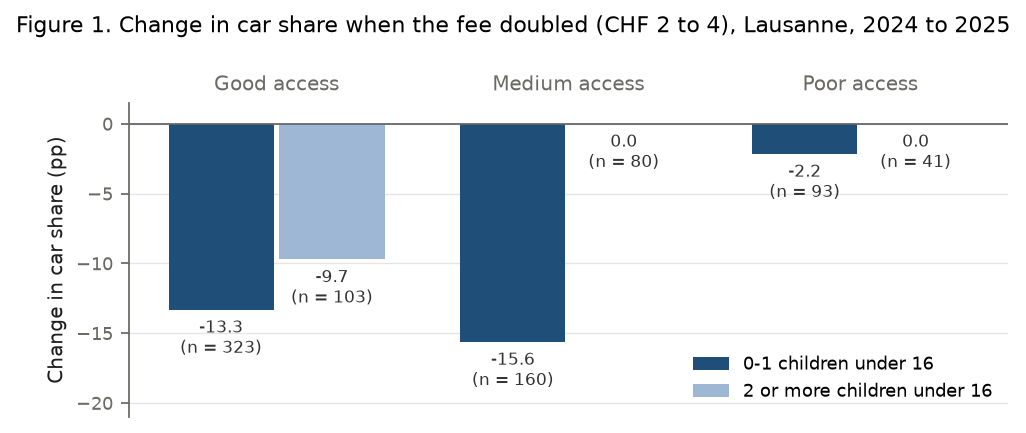

In [3]:
pp = (cell[2025] - cell[2024]) * 100
n = LS[LS.year == 2025].groupby(["transit_class", "kids"], observed=True).size()
fig, ax = plt.subplots(figsize=(6.4, 2.7))
x = np.arange(len(ORDER_T))
w = 0.36
cols = {"0-1": "#1F4E79", "2 or more": "#9DB7D5"}
for k, kd in enumerate(["0-1", "2 or more"]):
    xs = x + (k - 0.5) * (w + 0.02)
    vals = [pp[(c, kd)] for c in ORDER_T]
    ax.bar(xs, vals, w, color=cols[kd], label=f"{kd} children under 16")
    for xi, v, c in zip(xs, vals, ORDER_T):
        ax.text(xi, v - 0.6, f"{v:.1f}\n(n = {n[(c, kd)]})", ha="center", va="top", fontsize=7.5, color="#333333")
ax.axhline(0, color="#666666", linewidth=0.8)
ax.set_xticks(x, [f"{c} access" for c in ORDER_T], fontsize=9)
ax.xaxis.tick_top()
ax.tick_params(axis="x", length=0)
ax.set_ylabel("Change in car share (pp)", fontsize=9)
ax.set_ylim(-21, 1.5)
ax.spines[["bottom", "right"]].set_visible(False)
ax.yaxis.grid(True, color="#E5E5E5", linewidth=0.6)
ax.set_axisbelow(True)
ax.tick_params(axis="y", labelsize=8)
ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.suptitle("Figure 1. Change in car share when the fee doubled (CHF 2 to 4), Lausanne, 2024 to 2025",
             fontsize=10, x=0.01, ha="left")
fig.tight_layout()
FIGNOTE(fig, (
    "Note: Lausanne employees (N = 800), same employees in both years. Change in the share of employees whose main "
    "commuting mode is the car, 2025 minus 2024, in percentage points. Transit access = terciles of the public "
    "transport access score (Part A of the technical report), computed within the site. Before-after differences, "
    "not net of the Sion trend (+3.0 pp)."))

## Options compared

Table 1 projects every option with the same method (group elasticities observed in Lausanne, 2024 to 2025). The
technical report's central projection, which nets out the Sion trend (Table D1), predicts stronger responses: our
figures are on the cautious side.

In [4]:
fmt_int = lambda v: f"{v:,.0f}".replace(",", "'")
t1 = pd.DataFrame([{
    "Option": k,
    "Fee (CHF/day)": OPTIONS[k][0],
    "Car days per employee": f"{r['T']:.2f}",
    "Change (%)": "" if k.startswith("A.") else f"{100 * (r['T'] / T4 - 1):.1f}",
    "Drivers paying more": fmt_int(r["n_up"]),
    "Mean increase (CHF/year)": "" if r["n_up"] == 0 else fmt_int(r["extra"]),
    "Burden, poor access (%)": f"{r['b_poor']:.2f}",
    "Burden, low income (%)": f"{r['b_low']:.2f}",
    "Extra revenue (CHF/year)": "" if k.startswith("A.") else fmt_int(round(r["rev"] - REV4, -3)),
} for k, r in res.items()])
display(Markdown("**Table 1. Projected effects of the options, Lausanne site**" + 2 * chr(10) + t1.to_markdown(index=False, disable_numparse=True)))
NOTE((
    "Note: Lausanne site (N = 800 employees; 351 drivers in 2025). A is observed in 2025; other options are projected "
    "from 2025 with constant elasticities (share of drivers by transit access class x children 0-1 / 2 or more; days "
    "per driver by transit access class; Lausanne, 2024 to 2025). E: CHF 4 for poor access and for 2 or more children "
    "outside good access, CHF 8 otherwise. F, G: CHF 4 for the same groups and the lowest income tercile, CHF 6 (F) or "
    "8 (G) otherwise. Car days per employee: per week, non-drivers counted as 0. Change: vs 2025. Drivers paying more: "
    "2025 drivers whose fee rises; mean increase in annual spending if they keep driving. Burden: annual parking "
    "spending as % of observed gross income, mean over remaining drivers of the group. Extra revenue: annual revenue "
    "(fee x car days x 46 weeks) minus 2025 revenue (CHF 223'000)."))

**Table 1. Projected effects of the options, Lausanne site**

| Option                    | Fee (CHF/day)   | Car days per employee   | Change (%)   | Drivers paying more   | Mean increase (CHF/year)   | Burden, poor access (%)   | Burden, low income (%)   | Extra revenue (CHF/year)   |
|:--------------------------|:----------------|:------------------------|:-------------|:----------------------|:---------------------------|:--------------------------|:-------------------------|:---------------------------|
| A. Status quo             | 4               | 1.51                    |              | 0                     |                            | 0.80                      | 0.97                     |                            |
| B. Uniform                | 5               | 1.42                    | -6.5         | 351                   | 147                        | 0.99                      | 1.20                     | 38'000                     |
| C. Uniform                | 6               | 1.34                    | -11.3        | 351                   | 294                        | 1.18                      | 1.44                     | 74'000                     |
| D. Uniform                | 8               | 1.24                    | -18.0        | 351                   | 587                        | 1.55                      | 1.91                     | 143'000                    |
| E. No-alternative only    | 8 / 4           | 1.28                    | -15.5        | 190                   | 494                        | 0.80                      | 1.29                     | 38'000                     |
| F. Recommended 2026       | 6 / 4           | 1.40                    | -7.6         | 143                   | 255                        | 0.80                      | 0.97                     | 16'000                     |
| G. Step 2, 2027 if needed | 8 / 4           | 1.33                    | -11.9        | 143                   | 503                        | 0.80                      | 0.97                     | 29'000                     |

## Why this package

**Effectiveness.** In 2026 (F), car days per employee fall by about 8 % (1.51 to 1.40) and cars parked on an average
day from 242 to 224. With the second step (G), the reduction reaches 12 % (213 cars), as much as a uniform CHF 6.

**Distribution and acceptability.** Only 143 of the 351 drivers pay more, all with a realistic alternative and an
income above the lowest tercile. Poor access and low income drivers keep their 2025 burden (0.80 % and 0.97 % of
gross income). In 2026 the increase is about CHF 255 per year and nobody loses more than CHF 500. The rule fits in
one sentence: *those who can switch pay more, and every additional franc funds their alternative.*

**Who pays and who is protected.** 410 of the 800 employees (51 %) are eligible for the reduced rate, including 208
of the 351 current drivers. The 143 drivers who pay CHF 6 live in well served (92) or medium served (51)
municipalities and all belong to the middle or high income terciles; their mean gross income is about CHF 115'000,
against CHF 92'000 for drivers at the reduced rate. About 25 of them are expected to stop driving in 2026. The low
income criterion is the one that matters most for fairness: it adds 196 employees (47 drivers) who would otherwise
pay the standard rate.

**Revenue recycling, targeting and administration.** The additional revenue (about CHF 16'000 in 2026, CHF 29'000
with step 2) finances a contribution of **CHF 100 per annual public transport or bike subscription**, about 160
subscriptions in 2026. Priority goes first to employees who give up their parking, then to lowest income tercile
employees. The mobility manager pays it through the payroll on proof of subscription; the yearly budget is capped at
the additional revenue and the priority rules are set with the staff council. This makes the alternative cheaper for
those facing the higher fee; its effect is not in our projections.

**Administrative feasibility.** The rate depends on three items HR already holds: home municipality, children under
16 (family allowances) and salary per full-time equivalent. No declaration is needed. HR only transmits the rate
category (reduced or standard) to the parking system, so neither income nor family data leave HR. The list and
thresholds are updated yearly, and employees close to a threshold can ask for a review based on their documented
public transport travel time.

**Political feasibility.** The package is designed to be announced jointly by the mobility manager and the staff
council: the council co-decides the subscription rules and takes part in the 12-month review. The second step is not
automatic: it follows a rule published in advance, which limits the impression of a hidden programme of increases.
The message is simple: no employee without an alternative and no low income employee pays more, and the money
collected returns to employees.

**Alternatives rejected.** A **uniform CHF 6** (C) cuts car use a little more in 2026, but all 351 drivers pay more,
including poor access employees who cannot switch (burden 1.18 %) and low income drivers (1.44 %). A **uniform CHF 8**
(D) is the most effective (-18 %), but 204 drivers would lose more than CHF 500 per year. **Protecting only employees
without an alternative** (E) reaches -15 % but raises the burden of low income drivers to 1.29 %.

**Trade-off accepted.** Low income employees respond most to price, so keeping them at CHF 4 costs some reduction. We
accept it for the guarantee that no low income employee pays more, and target the subscription contribution at them.

**Uncertainty and limits of the evidence.** The evidence rests on one fee change over one year and on Sion as
counterfactual; group elasticities come from small cells (41 employees with poor access and two or more children);
CHF 8 lies outside the observed fee range, hence the conditional second step. The projections depend on the method:
for step 1, the reduction in car days ranges from 7 % (linear probability model, Table B3) to 9 % (elasticities net
of the Sion trend), and from 12 % to 14 % for step 2. A uniform CHF 6 ranges from 11 % to 17 %: it is clearly more
effective in 2026, and this is the price we pay for protecting the groups without an alternative. Our data say
nothing about welfare, public transport costs or CO2, which we therefore do not claim.

**Unintended effects.** Employees who give up their parking may park in nearby streets; some may be dropped off by
a family member, which still generates car trips. Thresholds create discontinuities: an employee just above CHF
80'800 per full-time equivalent, or living just above the poor access cut-off, pays the standard rate. Finally,
eligibility rules may encourage misreporting, which the use of HR records limits.

## Implementation and monitoring plan

Autumn 2025: publish the rule, the municipality list and the subscription scheme; HR assigns each employee a rate.
1 January 2026: step 1 in force. December 2026: joint review with the staff council and decision on the second step.

1. **Car days per employee** (parking access records), monthly, formal review at 6 and 12 months. Expected: 1.40.
   Trigger: above 1.33 after 12 months (12 % target missed): standard rate to CHF 8 in 2027; otherwise keep CHF 6.
2. **Car share of good access employees** (annual mode survey, autumn 2026, Sion as comparison). Expected: about
   25 % (29 % in 2025). Trigger: above 27 %: strengthen the alternatives (subscription contribution, bike parking)
   before or together with step 2.
3. **Parking spending as % of income of poor access and low income drivers** (payroll and parking records), yearly.
   Trigger: above their 2025 level (0.80 % and 0.97 %): revise the eligibility list or thresholds.

The mobility manager also counts cars parked in nearby streets before and after the change, to detect spillover.

In [5]:
# Check cell: numbers quoted in the text (not part of the memo)
for k in ["C. Uniform", "D. Uniform", "E. No-alternative only", "F. Recommended 2026",
          "G. Step 2, 2027 if needed"]:
    r = res[k]
    print(k, {kk: round(v, 3) for kk, v in r.items() if kk != "stay"}, "| extra rev", round(r["rev"] - REV4))
f, g = OPTIONS["F. Recommended 2026"][1], OPTIONS["G. Step 2, 2027 if needed"][1]
d0s = FEE_2025 * days0 * WEEKS
for name, fee in [("F", f), ("G", g), ("D", OPTIONS["D. Uniform"][1])]:
    r = fee / FEE_2025; st = r ** e_ext; ex = fee * days0 * r ** e_int * WEEKS - d0s
    print(name, "expected drivers losing > CHF 500/year:", round((st * (ex > 500)).sum(), 1))
n_good = (LS[LS.year == 2025].transit_class == "Good").sum()
print("expected good access car share under F (%):", round(100 * res["F. Recommended 2026"]["stay"][good].sum() / n_good, 1))
print("expected drivers who stop under F:", round(351 - res["F. Recommended 2026"]["stay"].sum(), 1))

C. Uniform {'T': np.float64(1.344), 'parked': np.float64(214.991), 'rev': np.float64(296687.249), 'n_up': np.int64(351), 'extra': np.float64(293.726), 'b_poor': np.float64(1.179), 'b_low': np.float64(1.439), 'b_kids': np.float64(1.208)} | extra rev 73698
D. Uniform {'T': np.float64(1.243), 'parked': np.float64(198.838), 'rev': np.float64(365862.32), 'n_up': np.int64(351), 'extra': np.float64(587.438), 'b_poor': np.float64(1.55), 'b_low': np.float64(1.907), 'b_kids': np.float64(1.584)} | extra rev 142873
E. No-alternative only {'T': np.float64(1.28), 'parked': np.float64(204.835), 'rev': np.float64(260939.522), 'n_up': np.int64(190), 'extra': np.float64(493.636), 'b_poor': np.float64(0.802), 'b_low': np.float64(1.294), 'b_kids': np.float64(1.022)} | extra rev 37950
F. Recommended 2026 {'T': np.float64(1.4), 'parked': np.float64(224.016), 'rev': np.float64(238780.006), 'n_up': np.int64(143), 'extra': np.float64(254.703), 'b_poor': np.float64(0.802), 'b_low': np.float64(0.968), 'b_kids': 